# 09 — Architecture comparison

**In short:** five more ImageNet-pretrained networks are fine-tuned exactly like the
EfficientNet-B0 baseline (notebook 08), so the only thing that changes between runs is
the architecture. Each run is scored the same way and saved, and notebook 10 puts them
side by side and tests an ensemble of the best ones.

| Architecture | Family | Why it is compared |
|---|---|---|
| `efficientnet_b0` | efficient CNN | baseline, trained in notebook 08 |
| `mobilenet_v3_large` | mobile CNN | smallest and fastest; candidate for running on the phone |
| `resnet50` | classic CNN | the standard reference in plant disease papers |
| `densenet121` | dense CNN | widely used in plant disease papers |
| `convnext_tiny` | modern CNN | strongest recent CNN design |
| `swin_t` | vision transformer | a different family from CNNs |

**Fair comparison:** same split, image size, augmentation, epochs, early stopping,
learning rate and seed for every run.

**Winning rule, fixed before any results:** the highest macro-F1 on the *field*
validation photos (FieldPlant + Tanzania) wins, with calibration error (ECE) as the
tie-breaker, provided size and CPU speed stay usable for the backend. PlantDoc is
reported but never used to choose.

**How to run:** set `ARCHITECTURE` in the settings cell, then *Run all*. One architecture
per run. To train the next one in the same session, change `ARCHITECTURE` and run again
from the settings cell; the image copy is reused. Progress is saved after every epoch,
so a disconnect resumes where it stopped.

**Needs a GPU runtime (T4).**

In [1]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis.git"
REPO_DIR = Path("/content/drive/MyDrive/Sproutly-app")

if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}

ML_DIR = REPO_DIR / "ml"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config

Mounted at /content/drive


In [2]:
# Keep the Drive copy of the repository in sync with GitHub.
!git -C {REPO_DIR} config core.fileMode false
!git -C {REPO_DIR} pull --ff-only
!git -C {REPO_DIR} status --short --branch

remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 956 bytes | 73.00 KiB/s, done.
From https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis
   54f01a4..d2f7794  main       -> origin/main
 * [new branch]      colab/compare-densenet121 -> origin/colab/compare-densenet121
Updating 54f01a4..d2f7794
Updating files: 100% (9/9), done.
Fast-forward
 ml/results/compare_mobilenet_v3_large/gradcam.png     | Bin 0 -> 1705277 bytes
 ml/results/compare_mobilenet_v3_large/history.csv     |  16 ++++++++++++++++
 ml/results/compare_mobilenet_v3_large/metrics.csv     |  11 +++++++++++
 ml/results/compare_mobilenet_v3_large/notebook.ipynb  |   1 +
 ml/results/compare_mobilenet_v3_large/settings.json   |  17 +++++++++++++++++
 ml/results/compare_mobilenet_v3_large/summary.json    |   9 +++++++++
 .../test_confusion_matrix.png                         | Bin 0

In [3]:
%pip install -q -r {ML_DIR}/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 130.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.3 MB/s eta 0:00:00


## Settings

Pick one of `mobilenet_v3_large`, `resnet50`, `densenet121`, `convnext_tiny`, `swin_t`.
Everything else is copied from the baseline and must not change between runs.
Set `FRESH_START = True` only to throw away an earlier attempt of the same architecture.

In [4]:
import importlib
import shutil

import torch

from src import training
importlib.reload(training)

ARCHITECTURE = "resnet50"
FRESH_START = False

assert ARCHITECTURE in training.ARCHITECTURES, f"Unknown architecture: {ARCHITECTURE}"
assert ARCHITECTURE != "efficientnet_b0", "EfficientNet-B0 is the baseline from notebook 08; no need to train it again."

RUN_NAME = f"compare_{ARCHITECTURE}"
TRAIN_SOURCES = ["plantvillage", "fieldplant", "tanzania"]
FIELD_SOURCES = ["fieldplant", "tanzania"]

# Identical to notebook 08 apart from the architecture.
SETTINGS = {
    "architecture": f"{ARCHITECTURE} (ImageNet weights: {training.ARCHITECTURES[ARCHITECTURE][1].name})",
    "image_size": 224,
    "batch_size": 64,
    "epochs": 15,
    "patience": 4,
    "learning_rate": 1e-3,
    "weight_decay": 1e-2,
    "seed": config.RANDOM_SEED,
    "train_sources": TRAIN_SOURCES,
}

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then run again."
DEVICE = "cuda"
SETTINGS["gpu"] = torch.cuda.get_device_name(0)
SETTINGS["torch"] = torch.__version__

RUN_DIR = config.MODELS_DIR / RUN_NAME
if FRESH_START and RUN_DIR.exists():
    shutil.rmtree(RUN_DIR)
RUN_DIR.mkdir(parents=True, exist_ok=True)
training.seed_everything(config.RANDOM_SEED)
print("Architecture:", ARCHITECTURE, "| run folder:", RUN_DIR, "| GPU:", SETTINGS["gpu"])

Architecture: resnet50 | run folder: /content/drive/MyDrive/CropDiseaseDiagnosis/models/compare_resnet50 | GPU: Tesla T4


## Load the split

The same CSVs as the baseline. Test keeps every source so results can be compared per source.

In [5]:
import pandas as pd

splits = {name: pd.read_csv(config.SPLITS_DIR / f"{name}.csv") for name in ["train", "val", "test", "ood_test", "unseen_test"]}
for name in ["train", "val"]:
    splits[name] = splits[name][splits[name]["source"].isin(TRAIN_SOURCES)]

CLASSES = list(config.PLANTVILLAGE_CLASSES)
assert set(splits["train"]["class"]) == set(CLASSES), "Every class must have training images"
display(pd.DataFrame({name: rows["source"].value_counts() for name, rows in splits.items()}).fillna(0).astype(int))

,train,val,test,ood_test,unseen_test
source,,,,,
fieldplant,618,125,146,0,0
plantdoc,0,0,0,953,371
plantvillage,8863,1876,1878,0,0
tanzania,1996,384,417,0,0


## Copy the images to local disk

About 10 minutes the first time in a session; instant for the second architecture.

In [6]:
from pathlib import Path

from src.data import image_dataset

LOCAL_ROOT = Path("/content/image_cache")
all_paths = sorted(set(pd.concat(splits.values())["path"]))
cached = image_dataset.cache_images(all_paths, config.RAW_DATA_DIR, LOCAL_ROOT)
assert cached == len(all_paths), f"Only {cached} of {len(all_paths)} images cached"
print("Cached", cached, "images in", LOCAL_ROOT)

Caching images:   0%|          | 0/17627 [00:00<?, ?it/s]

Cached 17627 images in /content/image_cache


In [7]:
from torch.utils.data import DataLoader

size = SETTINGS["image_size"]
datasets = {
    name: image_dataset.SplitDataset(
        rows, LOCAL_ROOT, CLASSES,
        image_dataset.train_transform(size) if name == "train" else image_dataset.eval_transform(size),
    )
    for name, rows in splits.items()
}
loaders = {
    name: DataLoader(ds, batch_size=SETTINGS["batch_size"], shuffle=name == "train", drop_last=name == "train",
                     num_workers=2, pin_memory=True, persistent_workers=True)
    for name, ds in datasets.items()
}
print({name: len(ds) for name, ds in datasets.items()})

{'train': 11477, 'val': 2385, 'test': 2441, 'ood_test': 953, 'unseen_test': 371}


## Train

Each line is one epoch. Small models take about 1–3 minutes per epoch on a T4; ConvNeXt and Swin take longer.

In [8]:
training.save_json(SETTINGS, RUN_DIR / "settings.json")
model = training.build_model(len(CLASSES), ARCHITECTURE)
history = training.fit(model, loaders["train"], loaders["val"], RUN_DIR, SETTINGS, DEVICE)
display(history.round(4))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 145MB/s]


Training:   0%|          | 0/179 [00:00<?, ?it/s]

Predicting:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 1/15: train loss 0.7127 | val loss 0.1949 | val acc 0.9405 | val macro-F1 0.9364  (best) | 1.4 min


...

Epoch 14/15: train loss 0.0109 | val loss 0.0356 | val acc 0.9899 | val macro-F1 0.9868  (best) | 1.5 min


Training:   0%|          | 0/179 [00:00<?, ?it/s]

Predicting:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 15/15: train loss 0.0097 | val loss 0.0353 | val acc 0.9899 | val macro-F1 0.9868 | 1.5 min


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_ece,minutes
0,1,0.7127,0.1949,0.9405,0.9364,0.0243,1.4132
1,2,0.2153,0.2354,0.9187,0.9162,0.0251,1.4021
2,3,0.1303,0.1464,0.9568,0.9519,0.0144,1.4785
3,4,0.1092,0.1527,0.9522,0.9551,0.0154,1.5009
4,5,0.0940,0.1529,0.9417,0.9424,0.0182,1.5033
5,6,0.0687,0.0848,0.9732,0.9710,0.0063,1.4869
6,7,0.0551,0.0830,0.9753,0.9706,0.0067,1.5304
7,8,0.0428,0.0708,0.9803,0.9755,0.0067,1.4803
8,9,0.0338,0.0550,0.9836,0.9802,0.0085,1.5207
9,10,0.0271,0.0404,0.9891,0.9863,0.0053,1.5231


## Training curves

Train and validation loss should fall together. Validation loss rising while train loss
keeps falling would mean overfitting; early stopping keeps the best epoch either way.

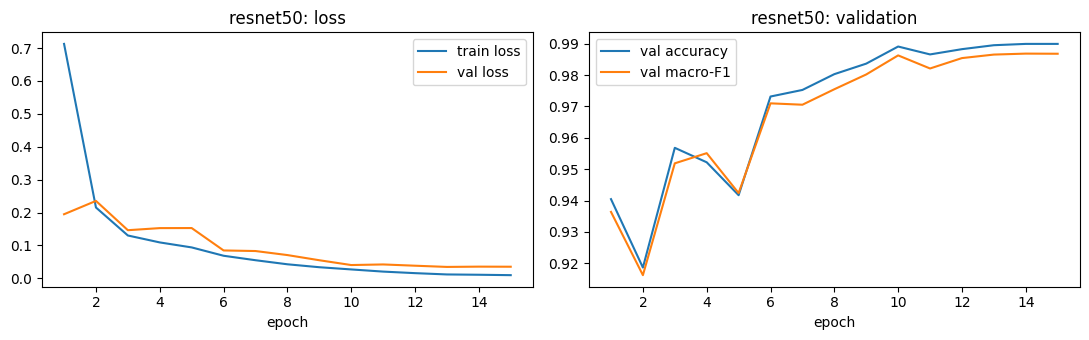

In [9]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(history["epoch"], history["train_loss"], label="train loss")
ax1.plot(history["epoch"], history["val_loss"], label="val loss")
ax1.set_xlabel("epoch"); ax1.legend(); ax1.set_title(f"{ARCHITECTURE}: loss")
ax2.plot(history["epoch"], history["val_accuracy"], label="val accuracy")
ax2.plot(history["epoch"], history["val_macro_f1"], label="val macro-F1")
ax2.set_xlabel("epoch"); ax2.legend(); ax2.set_title(f"{ARCHITECTURE}: validation")
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curves.png", dpi=150)
plt.show()

## Evaluate the best epoch

The row **`val: field`** is the one the winning rule uses. Test (overall and per source)
and PlantDoc (`ood_test`) are reported for every model the same way. Predictions and raw
scores (logits) are saved for the ensemble and for calibration.

In [ ]:
import numpy as np

from src import metrics

model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE))
model.to(DEVICE)
RESULTS_DIR = RUN_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

outputs, rows = {}, []
for name in ["val", "test", "ood_test", "unseen_test"]:
    logits, labels = training.predict(model, loaders[name], DEVICE)
    outputs[name] = training.save_predictions(splits[name], logits, CLASSES, RESULTS_DIR / f"{name}_predictions.csv")
    if name == "unseen_test":
        continue
    rows.append({"set": name, **metrics.summarise(logits, labels, len(CLASSES))})
    sources = splits[name]["source"].to_numpy()
    if name == "val":
        field = np.isin(sources, FIELD_SOURCES)
        rows.append({"set": "val: field", **metrics.summarise(logits[field], labels[field], len(CLASSES))})
    if name in ["val", "test"]:
        for source in sorted(set(sources)):
            mask = sources == source
            rows.append({"set": f"{name}: {source}", **metrics.summarise(logits[mask], labels[mask], len(CLASSES))})

results = pd.DataFrame(rows).set_index("set")
display(results.round(4))
results.to_csv(RESULTS_DIR / "metrics.csv")

unseen = outputs["unseen_test"]["confidence"]
print(f"Unseen tomato diseases ({len(unseen)} images): mean confidence {unseen.mean():.3f}, "
      f"{(unseen >= 0.9).mean():.1%} predicted with confidence >= 0.90")

Predicting:   0%|          | 0/38 [00:00<?, ?it/s]

Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

## Per-class results and confusion matrix (test)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

short = [c.replace("Corn_(maize)___", "Maize ").replace("___", " ").replace("_", " ") for c in CLASSES]
test_out = outputs["test"]
report = classification_report(test_out["class"], test_out["predicted"], labels=CLASSES, target_names=short,
                               digits=3, zero_division=0, output_dict=True)
report_table = pd.DataFrame(report).T.round(3)
display(report_table)
report_table.to_csv(RESULTS_DIR / "test_per_class.csv")

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(test_out["class"], test_out["predicted"], labels=CLASSES,
                                        display_labels=short, xticks_rotation=90, ax=ax, colorbar=False)
ax.set_title(f"{ARCHITECTURE}: test confusion matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

## Where the model looks (Grad-CAM)

Red areas pushed the model towards its answer. On a good model they sit on the lesions,
not the background. The same photos (fixed seed) are shown for every architecture:
top row field test photos, bottom row PlantDoc.

In [ ]:
from src import explain

def pick(name, sources, count):
    rows = splits[name].reset_index(drop=True)
    if sources:
        rows = rows[rows["source"].isin(sources)]
    rows = rows[rows["class"].isin(CLASSES)]
    return rows.sample(count, random_state=config.RANDOM_SEED).index.tolist()

examples = [("test", i) for i in pick("test", FIELD_SOURCES, 4)] + [("ood_test", i) for i in pick("ood_test", None, 4)]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, (name, i) in zip(axes.flat, examples):
    image, label = datasets[name][i]
    heatmap, predicted = explain.grad_cam(model, ARCHITECTURE, image.to(DEVICE))
    confidence = outputs[name].loc[i, "confidence"]
    ax.imshow(explain.to_picture(image, image_dataset.MEAN, image_dataset.STD))
    ax.imshow(heatmap, cmap="jet", alpha=0.4)
    mark = "right" if predicted == label else "WRONG"
    ax.set_title(f"true: {short[label]}\npredicted: {short[predicted]} ({confidence:.0%}, {mark})", fontsize=8)
    ax.axis("off")
plt.suptitle(f"{ARCHITECTURE}: Grad-CAM (top: field test photos, bottom: PlantDoc)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "gradcam.png", dpi=120)
plt.show()

## Size and speed

Parameters and file size decide whether the model could later run on a phone; CPU time
per image is what the backend (no GPU) will need. Timed on Colab's CPU with 2 threads,
so compare models with each other rather than with the laptop.

In [ ]:
summary = {
    "architecture": ARCHITECTURE,
    "parameters_millions": training.count_parameters(model) / 1e6,
    "best_epoch": int(history.loc[history["val_macro_f1"].idxmax(), "epoch"]),
    "epochs_run": len(history),
    "minutes_training": float(history["minutes"].sum()),
}
training.export(model.cpu(), CLASSES, SETTINGS["image_size"], image_dataset.MEAN, image_dataset.STD,
                RUN_DIR / "model.pt", SETTINGS, architecture=ARCHITECTURE)
summary["file_mb"] = (RUN_DIR / "model.pt").stat().st_size / 1e6
summary["cpu_ms_per_image"] = training.cpu_milliseconds_per_image(model, SETTINGS["image_size"])
training.save_json(summary, RESULTS_DIR / "summary.json")
display(pd.Series(summary))

## Copy the results into the repository

Weights stay on Drive; the small result files (metrics, curves, confusion matrix,
Grad-CAM, summary) go to `ml/results/<run>/` so they are visible on GitHub.

In [ ]:
REPO_RESULTS = ML_DIR / "results" / RUN_NAME
REPO_RESULTS.mkdir(parents=True, exist_ok=True)
for file in [RUN_DIR / "settings.json", RUN_DIR / "history.csv", RUN_DIR / "training_curves.png",
             RESULTS_DIR / "metrics.csv", RESULTS_DIR / "test_per_class.csv", RESULTS_DIR / "test_confusion_matrix.png",
             RESULTS_DIR / "gradcam.png", RESULTS_DIR / "summary.json"]:
    shutil.copy(file, REPO_RESULTS / file.name)
print(sorted(p.name for p in REPO_RESULTS.iterdir()))

## Make sure Drive has saved everything

Colab uploads files to Drive in the background; this waits until the upload has finished
(see DEF-01), then reconnects Drive for the push.

In [ ]:
drive.flush_and_unmount()
drive.mount("/content/drive")
print("Drive synced and remounted.")

## Save to GitHub

Save the notebook first (Ctrl+S). This keeps a copy of the run's notebook with its
outputs in the results folder and commits **only that folder** to a new branch, so this
notebook stays a clean template and the pull requests for different architectures never
conflict. Merge each pull request on GitHub as usual.

In [ ]:
from google.colab import userdata

from src import github_sync

shutil.copy(ML_DIR / "notebooks" / "09_architecture_comparison.ipynb", REPO_RESULTS / "notebook.ipynb")
print(github_sync.status(REPO_DIR))
print()
print(github_sync.push(
    REPO_DIR,
    branch=f"colab/{RUN_NAME.replace('_', '-')}",
    message=f"Train and evaluate {ARCHITECTURE} for the architecture comparison",
    token=userdata.get("GITHUB_TOKEN"),
    name="BilliartMuthoni",
    email=userdata.get("GIT_EMAIL"),
    paths=[str(REPO_RESULTS.relative_to(REPO_DIR))],
))